In [1]:
import pandas as pd
from parser import Tune
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from matplotlib import pyplot as plt

## Pull Data

In [2]:
data = open("data/data.txt", encoding="utf-8").read().strip()

tunes = Tune.parse_ireal_url(data, verbose=False)

In [3]:
print(tunes[9])

Title: A Blossom Fell
Composer: Barnes-Cornelius
Style: Ballad
Key: Bb
Transpose: 10
Comp style: Jazz-Ballad Swing
BPM: 60
Repeats: 0
Time signature: 4/4

Chord string:
[*AT44Bb6 sBo |lC-7 |F7 F7#5|Bb6 |Bb^7/D sDbo |lC-7 F7|C-7 F7|sBb6 Bo F7/C F7][*BlBb6 sBo |lC-7 |lF7 F7#5|Bb6 Bb7#5|Eb^7 |Bb^7/D |C-7 |Bb6 Bb7#5|Eb^7 Eb-6|Bb^7/D Dbo7|C-7 F7|Bb6 sC-7 F7

Flattened measures:
| Bb6, Bo     | C-7         | F7, F7#5    | Bb6         |
| Bb^7/D, Dbo | C-7, F7     | C-7, F7     | Bb6, Bo, F7/C, F7|
| Bb6, Bo     | C-7         | F7, F7#5    | Bb6, Bb7#5  |
| Eb^7        | Bb^7/D      | C-7         | Bb6, Bb7#5  |
| Eb^7, Eb-6  | Bb^7/D, Dbo7| C-7, F7     | Bb6, C-7, F7|



In [4]:
print(tunes[9].measures_as_strings)
print(tunes[5].measures_as_beats)
print(tunes[1].measure_sections)

['Bb6, Bo', 'C-7', 'F7, F7#5', 'Bb6', 'Bb^7/D, Dbo', 'C-7, F7', 'C-7, F7', 'Bb6, Bo, F7/C, F7', 'Bb6, Bo', 'C-7', 'F7, F7#5', 'Bb6, Bb7#5', 'Eb^7', 'Bb^7/D', 'C-7', 'Bb6, Bb7#5', 'Eb^7, Eb-6', 'Bb^7/D, Dbo7', 'C-7, F7', 'Bb6, C-7, F7']
[['A-7', ' ', ' '], ['Db^7', ' ', ' '], ['Bh7', ' ', ' '], ['E7#9', ' ', ' '], ['A-7', ' ', ' '], ['Db^7', ' ', ' '], ['Bh7', ' ', ' '], ['E7#9', ' ', ' '], ['C-7', ' ', ' '], ['F7b9', ' ', ' '], ['Bb^7', ' ', ' '], ['Ab-7', ' ', 'Db7'], ['F#h7', ' ', ' '], ['B7b9', ' ', ' '], ['E^7#5', ' ', ' '], ['E^7#5', 'E7', ' '], ['A-7', ' ', ' '], ['Db^7', ' ', ' '], ['Bh7', ' ', ' '], ['E7#9', ' ', ' '], ['A-7', ' ', ' '], ['Db^7', ' ', ' '], ['Bh7', ' ', ' '], ['E7#9', ' ', ' '], ['C-7', ' ', ' '], ['F7b9', ' ', ' '], ['Bb^7', ' ', ' '], ['Ab-7', ' ', 'Db7'], ['F#h7', ' ', ' '], ['B7b9', ' ', ' '], ['E-7', ' ', ' '], ['E-7', ' ', ' ']]
['A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'A', 'B', 'B', 'B', 'B', 'B', 'B', 'A', 'A', 'A', 'A', 'A', 'A', 'A

In [5]:
df = pd.DataFrame([tune.as_dict() for tune in tunes])

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1955 entries, 0 to 1954
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   title                1955 non-null   str   
 1   composer             1955 non-null   str   
 2   style                1955 non-null   str   
 3   key                  1955 non-null   str   
 4   transpose            1955 non-null   int64 
 5   comp_style           1955 non-null   str   
 6   bpm                  1955 non-null   str   
 7   repeats              1955 non-null   str   
 8   time_signature       1955 non-null   object
 9   chord_string         1955 non-null   str   
 10  measures_as_strings  1955 non-null   object
 11  measure_sections     1955 non-null   object
 12  measures_as_beats    1955 non-null   object
dtypes: int64(1), object(4), str(8)
memory usage: 198.7+ KB


## Train Transformer

In [7]:
from ireal_transformer import train_ireal_transformer

model, losses = train_ireal_transformer(tunes)

Tokenizing complete. Found 56 unique pitch class sets.


/home/ottenl/projects/jazz-transformer/ireal_transformer.py:100: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=layers)


Training on 2052 examples for 10 epochs...


100%|██████████| 10/10 [03:22<00:00, 20.30s/it]


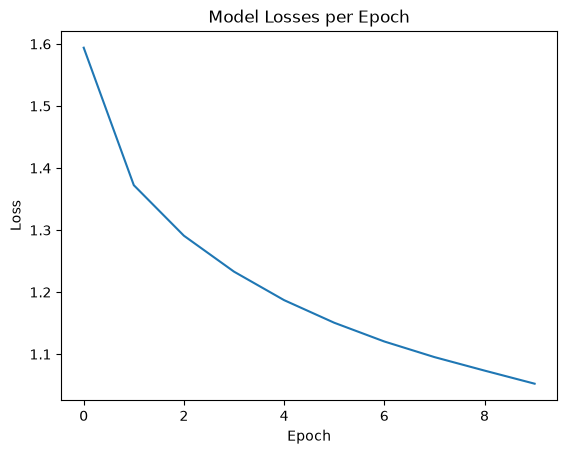

In [8]:
plt.plot(losses)
plt.title("Model Losses per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [9]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 568,535


In [ ]:
from ireal_transformer import save_ireal_transformer
from song_similarity import save_song_embeddings

save_ireal_transformer(model, "ireal_transformer_model.pth")
save_song_embeddings(model, tunes, "song_embeddings.json")